****

**Nombre:** Juan Martín Cusme Carrera

**Materia:** Recuperación de información

**Curso:** GR1CC

**Fecha:** 14/10/2026

****

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

## Carga del dataset iris

In [99]:
import sklearn
from sklearn import datasets

#Cargar el dataset de iris
iris = datasets.load_iris()

#Separar las características y las etiquetas
x_iris = iris.data
y_iris = iris.target

## ¿Qué representa cada instancia?

## Número de instancias y caracteristicas

## Dimensiones de la matriz de caracteristicas y el vector de etiquetas

In [100]:
#Número de instancias y características
instancias = x_iris.shape[0]
caracteristicas = x_iris.shape[1]
dimensiones_x_iris = x_iris.shape
dimensiones_y_iris = y_iris.shape

print(f"Número de instancias: {instancias}")
print(f"Número de características: {caracteristicas}")
print(f"Dimensiones de x_iris: {dimensiones_x_iris}")
print(f"Dimensiones de y_iris: {dimensiones_y_iris}")

Número de instancias: 150
Número de características: 4
Dimensiones de x_iris: (150, 4)
Dimensiones de y_iris: (150,)


El dataset tiene 150 instancias y 4 características. Cada instancia representa una flor de iris individual en donde cada una tiene cuatro características que nos dicen sus dimensiones físicas.

## Identificar las características y su significado

In [101]:
for i, nombre in enumerate(iris.feature_names, start=1):
    print(f"Característica {i}: {nombre}")

Característica 1: sepal length (cm)
Característica 2: sepal width (cm)
Característica 3: petal length (cm)
Característica 4: petal width (cm)


Las 4 caracteristicas son las dimensiones del pétalo y sépalo, teniendo el largo y el ancho de cada una en centimetros.

## Identificar las clases y la cantidad de ejemplos

In [102]:
import pandas as pd

nombres_clases = iris.target_names
contar_clases = pd.Series(y_iris).value_counts()

tabla_clases = pd.DataFrame({'Clase': nombres_clases, 'Cantidad': contar_clases.values})
print(tabla_clases)

        Clase  Cantidad
0      setosa        50
1  versicolor        50
2   virginica        50


Hay 3 clases las cuales son:

- Setosa
- Versicolor
- Virginica

Todas con la misma cantidad de elementos 

## Tabla con 5 ejemplos

In [103]:
df_iris = pd.DataFrame(x_iris, columns=iris.feature_names)

df_iris["especie"] = [
    iris.target_names[etiqueta] for etiqueta in y_iris
]

print (df_iris.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  especie  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


## Crear un gráfico de distribución de clases

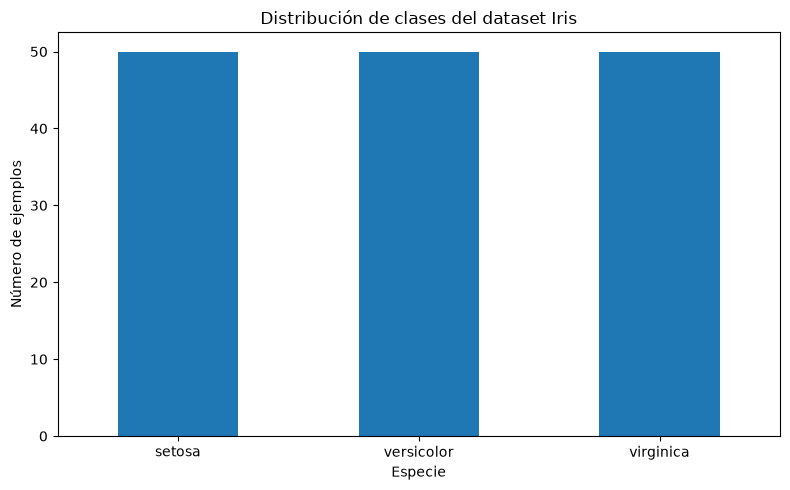

In [104]:
import matplotlib.pyplot as plt

conteo = df_iris["especie"].value_counts().reindex(iris.target_names)

plt.figure(figsize=(8, 5))
conteo.plot(kind="bar")

plt.title("Distribución de clases del dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Número de ejemplos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

## Preguntas

1. **¿Qué modelos crees que serán sensibles a las escalas de las características?**

Probablemente los modelos que son sensibles a las escalas sean el SMV lineal, MLP y gaussian naive bayes porque utilizan operaciones matemáticas y procesos de optimización que puede hacer que no predigan muy bien.

2. **¿Qué modelo esperas que produzca fronteras de decisión más simples?**

El SVM lineal y la regresión logistica porque producen fronteras lineales. También gaussian naive bayes porque puede producir fronteras cuadraticas.

3. **¿Por qué no podemos asegurar de antemano cuál será el mejor?**

Porque el rendimiento depende de la distribución de los datos, la capacidad del modelo para representar las relaciones entre las características, sus hiperparámetros y la partición utilizada. Que todo eso puede varias dependiendo con las herramientas con las que se trabaje en cuanto a los datos y los hiperparámetros escogidos.

## División del dataset para entrenamiento, validación y prueba

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    x_iris, y_iris,
    test_size=0.20,
    stratify=y_iris,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Entrenamiento:", X_train.shape[0])
print("Validación:", X_val.shape[0])
print("Prueba:", X_test.shape[0])

Entrenamiento: 90
Validación: 30
Prueba: 30


## Configuraciones iniciales de los clasificadores

Se entrena a los siete modelos usando los mismos datos. Se usa StandardScaler para normalizar las características. El escalamiento se calcula con entrenamiento para no usar información de validación o prueba.

In [106]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

modelos_clasificacion = {
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM lineal": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)),
    "Árbol de decisión": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)),
    "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20,), max_iter=2000, random_state=42))
}

## Entrenamiento y resultados de validación

In [107]:
resultados_validacion = []

for nombre, modelo in modelos_clasificacion.items():
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_val)
    accuracy = accuracy_score(y_val, predicciones)
    f1 = f1_score(y_val, predicciones, average="macro")
    resultados_validacion.append([nombre, accuracy, f1])

tabla_validacion = pd.DataFrame(resultados_validacion, columns=["Modelo", "Accuracy validación", "F1 macro validación"])
print(tabla_validacion.round(3).to_string(index=False))

             Modelo  Accuracy validación  F1 macro validación
        Naive Bayes                0.933                0.933
Regresión logística                0.933                0.933
         SVM lineal                0.933                0.933
  Árbol de decisión                0.900                0.900
      Random Forest                0.933                0.933
  Gradient Boosting                0.900                0.900
                MLP                0.933                0.933


## Ajustes limitados con validación

Solo se va a probar tres valores de C para el SVM y tres tamaños de capa oculta para el MLP. Además se compara su F1 macro en validación. En caso de obtener el mismo valor se deja la primera configuración hecha.

In [108]:
mejor_f1_svm = -1

for c in [0.1, 1, 10]:
    modelo = make_pipeline(StandardScaler(), SVC(kernel="linear", C=c))
    modelo.fit(X_train, y_train)
    f1 = f1_score(y_val, modelo.predict(X_val), average="macro")
    print(f"SVM con C={c}: F1 macro={f1:.3f}")

    if f1 > mejor_f1_svm:
        mejor_f1_svm = f1
        mejor_c = c

print("C seleccionado:", mejor_c)

SVM con C=0.1: F1 macro=0.933
SVM con C=1: F1 macro=0.933
SVM con C=10: F1 macro=0.900
C seleccionado: 0.1


In [109]:
mejor_f1_mlp = -1

for neuronas in [10, 20, 30]:
    modelo = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(neuronas,), max_iter=2000, random_state=42))
    modelo.fit(X_train, y_train)
    f1 = f1_score(y_val, modelo.predict(X_val), average="macro")
    print(f"MLP con {neuronas} neuronas: F1 macro={f1:.3f}")

    if f1 > mejor_f1_mlp:
        mejor_f1_mlp = f1
        mejores_neuronas = neuronas

print("Neuronas seleccionadas:", mejores_neuronas)

MLP con 10 neuronas: F1 macro=0.933
MLP con 20 neuronas: F1 macro=0.933
MLP con 30 neuronas: F1 macro=0.933
Neuronas seleccionadas: 10


## Evaluación final con la partición de prueba

Se seleccionaron las configuraciones con validación. Ahora se evalua en prueba por primera vez. No se cambian los modelos a partir de estos resultados.

In [110]:
# Reemplazar solamente las configuraciones que se ajustaron.
modelos_clasificacion["SVM lineal"] = make_pipeline(StandardScaler(), SVC(kernel="linear", C=mejor_c))
modelos_clasificacion["MLP"] = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(mejores_neuronas,), max_iter=2000, random_state=42))

modelos_clasificacion["SVM lineal"].fit(X_train, y_train)
modelos_clasificacion["MLP"].fit(X_train, y_train)

configuracion_clasificacion = {
    "Naive Bayes": "Por defecto",
    "Regresión logística": "max_iter=1000",
    "SVM lineal": f"C={mejor_c}",
    "Árbol de decisión": "max_depth=3",
    "Random Forest": "100 árboles, max_depth=3",
    "Gradient Boosting": "Por defecto",
    "MLP": f"{mejores_neuronas} neuronas, max_iter=2000"
}

resultados_prueba = []
predicciones_prueba = {}

for nombre, modelo in modelos_clasificacion.items():
    predicciones = modelo.predict(X_test)
    predicciones_prueba[nombre] = predicciones
    accuracy = accuracy_score(y_test, predicciones)
    f1 = f1_score(y_test, predicciones, average="macro")
    resultados_prueba.append([nombre, "StandardScaler", configuracion_clasificacion[nombre], accuracy, f1])

tabla_prueba = pd.DataFrame(resultados_prueba, columns=["Modelo", "Transformación", "Hiperparámetros principales", "Accuracy de prueba", "F1 macro de prueba"])
print(tabla_prueba.round(3).to_string(index=False))

             Modelo Transformación Hiperparámetros principales  Accuracy de prueba  F1 macro de prueba
        Naive Bayes StandardScaler                 Por defecto               0.933               0.933
Regresión logística StandardScaler               max_iter=1000               0.933               0.933
         SVM lineal StandardScaler                       C=0.1               0.933               0.933
  Árbol de decisión StandardScaler                 max_depth=3               0.933               0.933
      Random Forest StandardScaler    100 árboles, max_depth=3               0.933               0.933
  Gradient Boosting StandardScaler                 Por defecto               0.967               0.967
                MLP StandardScaler  10 neuronas, max_iter=2000               0.900               0.900


## Matrices de confusión de Naive Bayes, SVM y MLP

En las matrices, las filas son las clases reales y las columnas son las clases predichas.

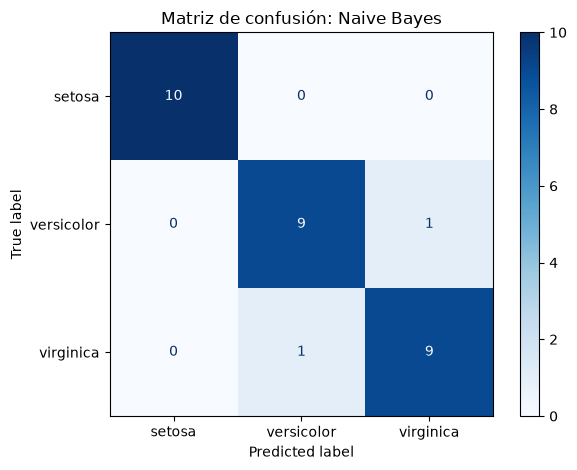

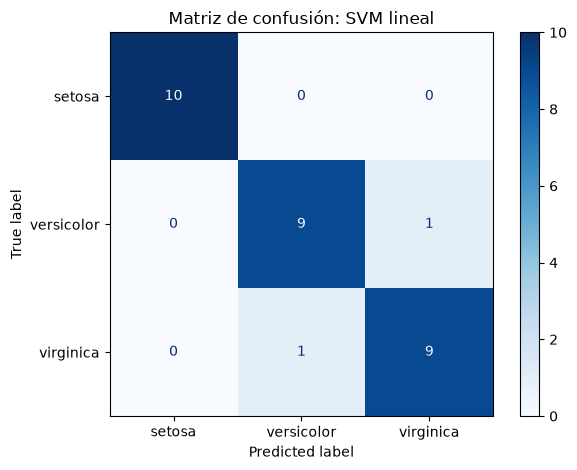

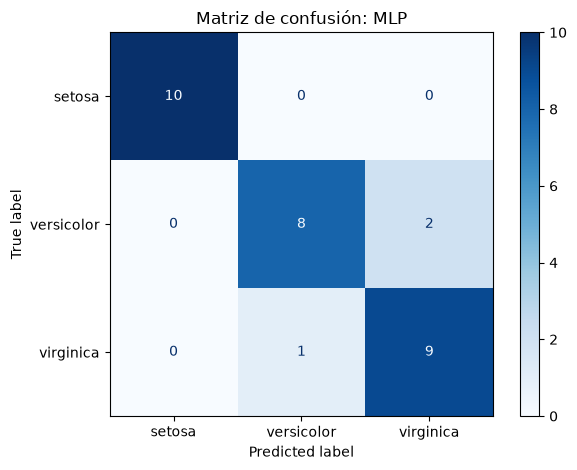

In [111]:
from sklearn.metrics import ConfusionMatrixDisplay

for nombre in ["Naive Bayes", "SVM lineal", "MLP"]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones_prueba[nombre],
        display_labels=iris.target_names, cmap="Blues"
    )
    plt.title("Matriz de confusión: " + nombre)
    plt.tight_layout()
    plt.show()

## Dos errores de clasificación

Para revisar ejemplos concretos se usarán los errores de Naive Bayes ya que la salida muestra las medidas de las flores que clasificó incorrectamente.

In [112]:
indices_errores = np.where(predicciones_prueba["Naive Bayes"] != y_test)[0]

for indice in indices_errores[:2]:
    print("Ejemplo:", indice)
    print("Clase real:", iris.target_names[y_test[indice]])
    print("Clase predicha:", iris.target_names[predicciones_prueba["Naive Bayes"][indice]])
    print(pd.Series(X_test[indice], index=iris.feature_names))
    print()

Ejemplo: 23
Clase real: virginica
Clase predicha: versicolor
sepal length (cm)    6.1
sepal width (cm)     2.6
petal length (cm)    5.6
petal width (cm)     1.4
dtype: float64

Ejemplo: 25
Clase real: versicolor
Clase predicha: virginica
sepal length (cm)    6.7
sepal width (cm)     3.0
petal length (cm)    5.0
petal width (cm)     1.7
dtype: float64



## Interpretación

1. **¿Cuál fue el modelo con mejor desempeño?** 

Gradient Boosting obtuvo el mejor resultado con un accuracy y F1 macro de 0.967.

2. **¿Cuál fue el más sencillo de programar?** 

Para mí fue Gaussian Naive Bayes porque se puede entrenar y utilizar sin tener que configurar muchos hiperparámetros.

3. **¿Accuracy y F1 macro cuentan la misma historia?** 

Si porque en estos resultados sus valores son muy parecidos porque las tres clases tienen la misma cantidad de flores y los errores están repartidos entre ellas. Pero accuracy calcula el total de aciertos y F1 macro promedia el F1 de cada clase.

4. **¿Cuál es la diferencia entre macro y micro?** 

Macro calcula la métrica de cada clase y luego obtiene el promedio. Micro junta todos los aciertos y errores antes de calcularla. En este problema, F1 micro es igual a accuracy.

5. **¿Qué aporta el MLP frente a un modelo lineal?** 

El MLP puede aprender relaciones no lineales entre las características, aunque necesita más parámetros y no siempre obtiene mejores resultados. En este caso no superó a los otros modelos.

**Análisis de los dos errores de Naive Bayes:** 

La flor del ejemplo 23 era *virginica*, pero se predijo *versicolor*. Su pétalo tenía 5.6 cm de largo y 1.4 cm de ancho. Ese ancho es más parecido al de muchas *versicolor*, aunque el largo es propio de muchas *virginica*. En el ejemplo 25 ocurrió lo contrario: era *versicolor* y se predijo *virginica*, con un pétalo de 5.0 cm de largo y 1.7 cm de ancho. Sus dimensiones están entre las dos clases, lo que podría causar confusión. Igualmente no se puede asegurar que esas medidas sean la causa exacta del error porque el modelo usa las cuatro características.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

## Carga del dataset Diabetes

In [113]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
x_diabetes = diabetes.data
y_diabetes = diabetes.target

print("Instancias:", x_diabetes.shape[0])
print("Características:", x_diabetes.shape[1])
print("Dimensiones de X:", x_diabetes.shape)
print("Dimensiones de y:", y_diabetes.shape)
print("Variables:", diabetes.feature_names)

Instancias: 442
Características: 10
Dimensiones de X: (442, 10)
Dimensiones de y: (442,)
Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


Cada instancia representa a un paciente. El objetivo es un valor numérico que mide la progresión de la diabetes un año después de las primeras mediciones. Las 10 variables son la edad, sexo, índice de masa corporal, presión arterial y seis medidas relacionadas con la sangre como s1.

En la descripción de sklearn indica que las características ya fueron centradas y escaladas por lo que se puede decir que los valores no corresponden a las unidades médicas originales.

## Comprobar las transformaciones en la descripción del dataset

In [114]:
# Mostrar la parte de la descripción que indica cómo se transformaron los datos.
for linea in diabetes.DESCR.splitlines():
    if "mean centered" in linea or "standard deviation" in linea:
        print(linea)

Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1).


Nos dice que ya fueron centradas y escaladas con la desviación estandar multiplicada por la raíz cuadrada de n_samples.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No creo que un modelo más flexible siempre tenga menos error en datos nuevos. Aunque puede aprender mejor en el entrenamiento, también puede memorizar el ruido y equivocarse al predecir datos que no conoce que basicamente es overfitting.

## División en entrenamiento, validación y prueba

In [115]:
X_dev_reg, X_test_reg, y_dev_reg, y_test_reg = train_test_split(
    x_diabetes, y_diabetes, test_size=0.20, random_state=42
)

X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_dev_reg, y_dev_reg, test_size=0.25, random_state=42
)

print("Entrenamiento:", X_train_reg.shape[0])
print("Validación:", X_val_reg.shape[0])
print("Prueba:", X_test_reg.shape[0])

Entrenamiento: 264
Validación: 89
Prueba: 89


## Configuraciones iniciales de los modelos

Se utiliza otra vez StandardScaler para regresión lineal, Ridge, Lasso, kNN y MLP. Los modelos basados en árboles no necesitan ese escalamiento.

In [116]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modelos_regresion = {
    "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Árbol de regresión": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(20,), max_iter=2000, random_state=42))
}

## Entrenar modelos y comparar en validación

Para comparar el error se usó MAE, RMSE y R^2. En RMSE y MAE, un valor menor es mejor; para R^2, un valor más cercano a 1 es mejor.

In [117]:
resultados_reg_val = []

for nombre, modelo in modelos_regresion.items():
    modelo.fit(X_train_reg, y_train_reg)
    predicciones = modelo.predict(X_val_reg)
    mae = mean_absolute_error(y_val_reg, predicciones)
    rmse = np.sqrt(mean_squared_error(y_val_reg, predicciones))
    r2 = r2_score(y_val_reg, predicciones)
    resultados_reg_val.append([nombre, mae, rmse, r2])

tabla_reg_val = pd.DataFrame(resultados_reg_val, columns=["Modelo", "MAE validación", "RMSE validación", "R^2 validación"])
print(tabla_reg_val.round(3).to_string(index=False))

            Modelo  MAE validación  RMSE validación  R^2 validación
  Regresión lineal          42.939           51.194           0.522
             Ridge          42.723           51.103           0.523
             Lasso          42.642           51.100           0.523
               kNN          45.292           56.833           0.410
Árbol de regresión          47.237           59.761           0.348
     Random Forest          44.175           54.700           0.454
 Gradient Boosting          44.616           53.907           0.470
               MLP          48.273           58.001           0.386


c:\Users\DETPC\Desktop\ir26b\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


Nota: No es un error solamente una advertencia de que el modelo MLP no convergió en las 2000 iteraciones, no es error de ejecución pero si puede interferir en el despempeño del modelo a la hora de predecir.

## Comparación de regularización de Ridge y Lasso

Se prueba distintas penalizaciones y se selecciona el valor con menor RMSE en la validación. También se compara el RMSE de entrenamiento, la suma de valores absolutos de los coeficientes y cuántos coeficientes son cero.

In [118]:
resultados_regularizacion = []
mejor_rmse_ridge = float("inf")
mejor_rmse_lasso = float("inf")

for nombre in ["Ridge", "Lasso"]:
    if nombre == "Ridge":
        alphas = [0.1, 1, 10, 100]
    else:
        alphas = [0.01, 0.1, 1, 10]

    for alpha in alphas:
        if nombre == "Ridge":
            modelo = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        else:
            modelo = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

        modelo.fit(X_train_reg, y_train_reg)
        rmse_train = np.sqrt(mean_squared_error(y_train_reg, modelo.predict(X_train_reg)))
        rmse_val = np.sqrt(mean_squared_error(y_val_reg, modelo.predict(X_val_reg)))
        coeficientes = modelo[-1].coef_
        magnitud = np.abs(coeficientes).sum()
        cantidad_ceros = np.sum(coeficientes == 0)
        resultados_regularizacion.append([nombre, alpha, magnitud, cantidad_ceros, rmse_train, rmse_val])

        if nombre == "Ridge" and rmse_val < mejor_rmse_ridge:
            mejor_rmse_ridge = rmse_val
            mejor_alpha_ridge = alpha
        if nombre == "Lasso" and rmse_val < mejor_rmse_lasso:
            mejor_rmse_lasso = rmse_val
            mejor_alpha_lasso = alpha

tabla_regularizacion = pd.DataFrame(resultados_regularizacion, columns=["Modelo", "Alpha", "Magnitud coef.", "Coef. en cero", "RMSE entrenamiento", "RMSE validación"])
print(tabla_regularizacion.round(3).to_string(index=False))
print("Mejor alpha de Ridge:", mejor_alpha_ridge)
print("Mejor alpha de Lasso:", mejor_alpha_lasso)

Modelo  Alpha  Magnitud coef.  Coef. en cero  RMSE entrenamiento  RMSE validación
 Ridge   0.10         192.447              0              54.611           51.174
 Ridge   1.00         156.990              0              54.644           51.103
 Ridge  10.00         108.883              0              54.843           51.160
 Ridge 100.00          87.803              0              55.859           51.737
 Lasso   0.01         193.487              0              54.611           51.178
 Lasso   0.10         150.425              0              54.654           51.100
 Lasso   1.00         100.612              1              54.912           51.060
 Lasso  10.00          52.749              6              58.425           53.151
Mejor alpha de Ridge: 1
Mejor alpha de Lasso: 1


## Modelos finales y resultados en prueba

Se fija los valores seleccionados con la validación y la prueba se utiliza solo para mostrar que tan buenos fueron los ocho modelos.

In [119]:
modelos_regresion["Ridge"] = make_pipeline(StandardScaler(), Ridge(alpha=mejor_alpha_ridge))
modelos_regresion["Lasso"] = make_pipeline(StandardScaler(), Lasso(alpha=mejor_alpha_lasso, max_iter=10000))

modelos_regresion["Ridge"].fit(X_train_reg, y_train_reg)
modelos_regresion["Lasso"].fit(X_train_reg, y_train_reg)

resultados_reg_prueba = []
predicciones_reg_prueba = {}

for nombre, modelo in modelos_regresion.items():
    predicciones = modelo.predict(X_test_reg)
    predicciones_reg_prueba[nombre] = predicciones
    mae = mean_absolute_error(y_test_reg, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test_reg, predicciones))
    r2 = r2_score(y_test_reg, predicciones)
    resultados_reg_prueba.append([nombre, mae, rmse, r2])

tabla_reg_prueba = pd.DataFrame(resultados_reg_prueba, columns=["Modelo", "MAE", "RMSE", "R²"])
print(tabla_reg_prueba.round(3).to_string(index=False))

            Modelo    MAE   RMSE    R²
  Regresión lineal 42.924 54.156 0.446
             Ridge 42.970 54.031 0.449
             Lasso 42.722 53.302 0.464
               kNN 41.672 54.105 0.447
Árbol de regresión 47.766 62.388 0.265
     Random Forest 43.991 54.418 0.441
 Gradient Boosting 44.567 54.791 0.433
               MLP 45.956 56.861 0.390


## Gráficos de valores reales y predicciones

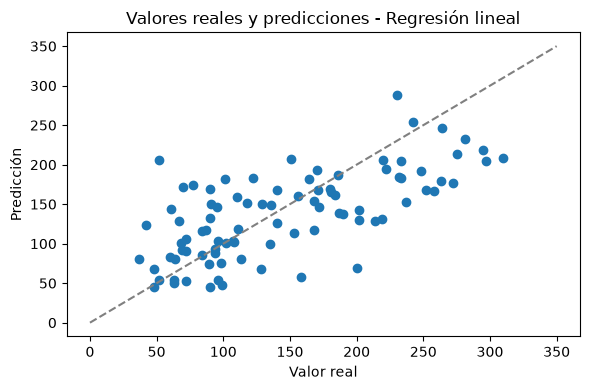

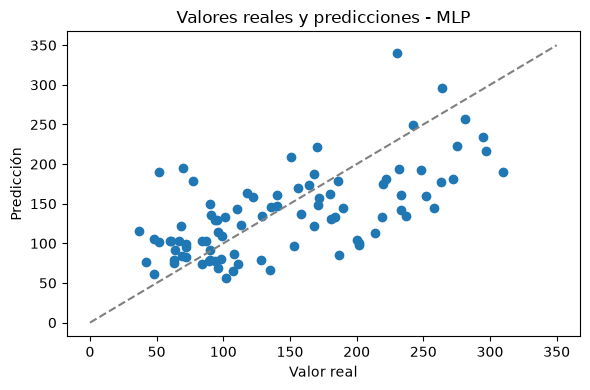

In [120]:
for nombre in ["Regresión lineal", "MLP"]:
    predicciones = predicciones_reg_prueba[nombre]
    plt.figure(figsize=(6, 4))
    plt.scatter(y_test_reg, predicciones)
    plt.plot([0, 350], [0, 350], "--", color="gray")
    plt.xlabel("Valor real")
    plt.ylabel("Predicción")
    plt.title("Valores reales y predicciones - " + nombre)
    plt.tight_layout()
    plt.show()

## Gráficos de residuos

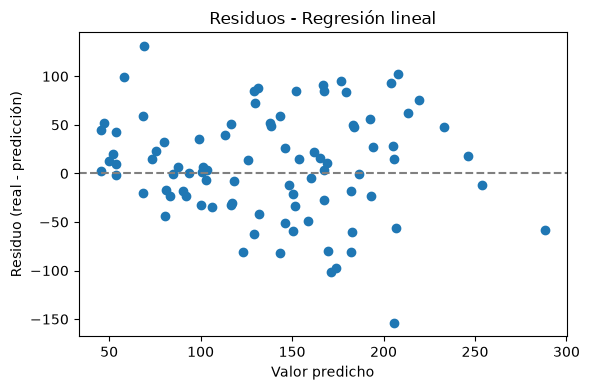

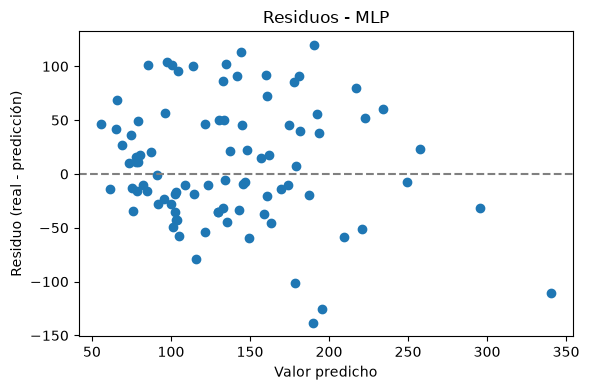

In [121]:
for nombre in ["Regresión lineal", "MLP"]:
    predicciones = predicciones_reg_prueba[nombre]
    residuos = y_test_reg - predicciones
    plt.figure(figsize=(6, 4))
    plt.scatter(predicciones, residuos)
    plt.axhline(0, linestyle="--", color="gray")
    plt.xlabel("Valor predicho")
    plt.ylabel("Residuo (real - predicción)")
    plt.title("Residuos - " + nombre)
    plt.tight_layout()
    plt.show()

## Dos errores absolutos grandes de regresión lineal y MLP

Para cada modelo se muestra los dos pacientes con mayor diferencia absoluta entre el valor real y el valor predicho y sus 10 características transformadas.

In [122]:
for nombre in ["Regresión lineal", "MLP"]:
    predicciones = predicciones_reg_prueba[nombre]
    errores_absolutos = np.abs(y_test_reg - predicciones)
    indices = np.argsort(errores_absolutos)[-2:][::-1]

    print("Modelo:", nombre)
    for indice in indices:
        print("Ejemplo:", indice)
        print("Valor real:", y_test_reg[indice])
        print("Predicción:", round(predicciones[indice], 2))
        print("Error absoluto:", round(errores_absolutos[indice], 2))
        print(pd.Series(X_test_reg[indice], index=diabetes.feature_names).round(3))
        print()

Modelo: Regresión lineal
Ejemplo: 61
Valor real: 52.0
Predicción: 205.66
Error absoluto: 153.66
age   -0.042
sex   -0.045
bmi    0.041
bp    -0.026
s1    -0.032
s2    -0.030
s3    -0.036
s4     0.003
s5     0.034
s6    -0.018
dtype: float64

Ejemplo: 46
Valor real: 200.0
Predicción: 68.97
Error absoluto: 131.03
age   -0.096
sex   -0.045
bmi   -0.036
bp    -0.075
s1    -0.039
s2    -0.028
s3     0.016
s4    -0.039
s5    -0.074
s6    -0.001
dtype: float64

Modelo: MLP
Ejemplo: 61
Valor real: 52.0
Predicción: 190.1
Error absoluto: 138.1
age   -0.042
sex   -0.045
bmi    0.041
bp    -0.026
s1    -0.032
s2    -0.030
s3    -0.036
s4     0.003
s5     0.034
s6    -0.018
dtype: float64

Ejemplo: 1
Valor real: 70.0
Predicción: 195.44
Error absoluto: 125.44
age    0.093
sex   -0.045
bmi    0.037
bp     0.022
s1    -0.025
s2    -0.017
s3     0.001
s4    -0.039
s5    -0.023
s6    -0.022
dtype: float64



## Interpretación del apartado 3

1. **¿Qué modelo tuvo el mejor desempeño?** 

Lasso tuvo el menor RMSE de 53.30 y el mayor R^2 de 0.464 pero por el otro lado knn tuvo el menor MAE de 41.672. Por eso depende de la métrica que usemos para comparar.

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?** 

Porque MAE calcula el promedio de los errores absolutos mientras que RMSE da más importancia a los errores grandes.

3. **¿Cómo se interpreta un R² negativo?** 

Significa que el modelo está prediciendo peor que si usáramos el promedio de los valores de prueba como predicción para todos los ejemplos.

4. **¿Qué efecto tuvo aumentar la regularización?** 

En Ridge y Lasso, al aumentar al valor de alpha se redujo la magnitud de los coeficientes. En Lasso con alpha=10, seis coeficientes quedaron en cero y subió el error de la validación. Por eso una regularización demasiado grande también hacer que el modelo no prediga bien.

5. **¿Qué puede explicar los errores grandes?** 

Por ejemplo en la regresión lineal el paciente del ejemplo 61 tenía un valor real de 52, pero el modelo predijo 205.66. Podría ser por factores que no están registrados en el dataset o a relaciones difíciles de aprender para el modelo de regresión pero no puedo saber la causa exacta solo viendo sus datos. El MLP también se equivocó bastante con ese paciente.

6. **¿Un coeficiente predictivo demuestra una relación causal?** 

No ya que una variable puede servir para predecir y estar relacionada con la progresión de la diabetes pero eso no demuestra que esa especificamente la cause.